# Running Microbe Regressions
While we can run the regressions as done before, I will also try exporting a metadata df and an abundance df for use in R with radEmu. 

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats.mstats

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
import statsmodels.api as sm
from regression_functions import *
from statannotations.Annotator import Annotator

## Read in data

In [2]:
# Read and sort abx use data
abx_covar = pd.read_csv("../data/abx_covariates_with_statins_a1c_all_covars.csv")
abx_covar = abx_covar.sort_values(by="days_in_program")

In [3]:
len(abx_covar)

1970

In [4]:
counts = pd.read_csv("../data/rh_abx_genus_level_counts.csv", dtype={"public_client_id":str})

## Create microbe name dictionary for plotting
(Made this after running regressions but moving up here for visibility)

In [5]:
microbe_dict = {'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera': 'Methanosphaera',
                'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter':'Methanobrevibacter',
                'Bacteria_Actinobacteria_Actinobacteria_Bifidobacteriales_Bifidobacteriaceae_Bifidobacterium':'Bifidobacterium',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Atopobium':'Atopobium',
                'Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces':'Actinomyces',
                'Bacteria_Actinobacteria_Actinobacteria_Micrococcales_Micrococcaceae_Rothia':'Rothia',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriaceae_Collinsella':'Collinsella',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_nan': 'Coriobacteriales_Incertae_Sedis',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Adlercreutzia':'Adlercreutzia',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Eggerthella': 'Eggerthella',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_DNF00809':'Eggerthellaceae_DNF00809',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Enterorhabdus':'Enterorhabdus',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Gordonibacter':'Gordonibacter',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Senegalimassilia': 'Senegalimassilia',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Slackia': 'Slackia',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_nan': 'Eggerthellaceae',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_nan_nan': 'Coriobacteriales',
                'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_Raoultibacter':'Incertae_Sedis_Raoultibacter',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides':'Bacteroides',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Barnesiella': 'Barnesiella',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Coprobacter': 'Coprobacter',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_nan': 'Barnesiellaceae',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Butyricimonas': 'Butyricimonas',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Odoribacter':'Odoribacter',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Sanguibacteroides': 'Sanguibacteroides',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Muribaculaceae_nan': 'Muribaculaceae',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Alloprevotella':'Alloprevotella',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotellaceae_NK3B31_group': 'Prevotellaceae_NK3B31_group',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Paraprevotella':'Paraprevotella',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella':'Prevotella',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_7':'Prevotella_7',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_9':'Prevotella_9',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_nan_nan':'Bacteroidales',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Alistipes':'Alistipes',
                'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides':'Parabacteroides',
                'Bacteria_Bacteroidetes_Bacteroidia_Flavobacteriales_nan_nan': 'Flavobacteriales',
                'Bacteria_Cyanobacteria_Oxyphotobacteria_Chloroplast_nan_nan':'Oxyphotobacteria_Chloroplast',
                'Bacteria_Cyanobacteria_Melainabacteria_Gastranaerophilales_nan_nan': 'Gastranaerophilales',
                'Bacteria_Firmicutes_Bacilli_Bacillales_Staphylococcaceae_Staphylococcus': 'Staphylococcus',
                'Bacteria_Firmicutes_Bacilli_Bacillales_Family_XI_Gemella':'Gemella',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Carnobacteriaceae_Granulicatella':'Granulicatella',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Enterococcaceae_Enterococcus':'Enterococcus',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Pediococcus': 'Pediococcus',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Lactobacillus':'Lactobacillus',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Leuconostoc':'Leuconostoc',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Lactococcus':'Lactococcus',
                'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Streptococcus':'Streptococcus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Catabacter':'Catabacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group':'Christensenellaceae_R7',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_nan':'Christensenellaceae',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiaceae_1_Clostridium_sensu_stricto_1':'Clostridium_sensu_stricto_1',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiales_vadinBB60_group_nan':'Clostridiales_vadinBB60',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Defluviitaleaceae_Defluviitaleaceae_UCG011': 'Defluviitaleaceae_UCG011',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Anaerofustis':'Anaerofustis',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Eubacterium':'Eubacterium',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Anaerococcus':'Anaerococcus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Ezakiella':'Ezakiella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Finegoldia':'Finegoldia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Murdochiella': 'Murdochiella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Peptoniphilus':'Peptoniphilus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_AD3011_group':'Clostridiales_Family_XIII_AD3011',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_UCG001':'Clostridiales_Family_XIII_UCG001',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_nan':'Clostridiales_Family_XIII',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerosporobacter': 'Anaerosporobacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Agathobacter':'Agathobacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerostipes':'Anaerostipes',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Blautia':'Blautia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_CAG56': 'Lachnospiraceae_CAG56',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_1':'Coprococcus_1',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_2':'Coprococcus_2',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_3':'Coprococcus_3',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Cuneatibacter': 'Cuneatibacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Dorea': 'Dorea',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Eisenbergiella': 'Eisenbergiella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Fusicatenibacter':'Fusicatenibacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_FD2005': 'Lachnospiraceae_FD2005',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066575':'Lachnospiraceae_GCA900066575',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Herbinix': 'Herbinix',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Hungatella': 'Hungatella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnoclostridium':'Lachnoclostridium',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospira':'Lachnospira',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_AC2044_group': 'Lachnospiraceae_AC2044_group',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_FCS020_group':'Lachnospiraceae_FCS020',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066755':'Lachnospiraceae_GCA900066755',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_ND3007_group':'Lachnospiraceae_ND3007',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4A136_group':'Lachnospiraceae_NK4A136',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4B4_group': 'Lachnospiraceae_NK4B4_group',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_nan':'Lachnospiraceae',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG001':'Lachnospiraceae_UCG001',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG003': 'Lachnospiraceae_UCG003',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG004':'Lachnospiraceae_UCG004',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG008': 'Lachnospiraceae_UCG008',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG010':'Lachnospiraceae_UCG010',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Howardella':'Howardella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lactonifactor': 'Lactonifactor',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Marvinbryantia':'Marvinbryantia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Roseburia':'Roseburia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas': 'Sellimonas',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Shuttleworthia':'Shuttleworthia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Syntrophococcus': 'Syntrophococcus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella':'Tyzzerella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_3': 'Tyzzerella_3',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_4': 'Tyzzerella_4',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_UC512E3':'Lachnospiraceae_UC512E3',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Intestinibacter':'Intestinibacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Terrisporobacter':'Terrisporobacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Peptococcus': 'Peptococcus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_nan': 'Peptococcaceae',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Romboutsia':'Romboutsia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Acetanaerobacterium':'Acetanaerobacterium',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerofilum': 'Anaerofilum',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Angelakisella': 'Angelakisella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerotruncus':'Anaerotruncus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Butyricicoccus':'Butyricicoccus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Caproiciproducens':'Caproiciproducens',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Candidatus_Soleaferrea':'Candidatus_Soleaferrea',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_CAG352':'Ruminococcaceae_CAG352',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_DTU089':'Ruminococcaceae_DTU089',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Faecalibacterium':'Faecalibacterium',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Flavonifractor':'Flavonifractor',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Fournierella': 'Fournierella',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_GCA900066225': 'Ruminococcaceae_GCA900066225',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Harryflintia':'Harryflintia',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Hydrogenoanaerobacterium': 'Hydrogenoanaerobacterium',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Intestinimonas':'Intestinimonas',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Negativibacillus':'Negativibacillus',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillibacter':'Oscillibacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillospira':'Oscillospira',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Papillibacter': 'Papillibacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Phocea':'Phocea',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pseudoflavonifractor':'Pseudoflavonifractor',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pygmaiobacter': 'Pygmaiobacter',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_NK4A214_group':'Ruminococcaceae_NK4A214',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium': 'Ruminiclostridium',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_1': 'Ruminiclostridium_1',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_5':'Ruminiclostridium_5',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_6': 'Ruminiclostridium_6',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_9':'Ruminiclostridium_9',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG002':'Ruminococcaceae_UCG002',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG003':'Ruminococcaceae_UCG003',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG004':'Ruminococcaceae_UCG004',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG005':'Ruminococcaceae_UCG005',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG007': 'Ruminococcaceae_UCG007',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG008': 'Ruminococcaceae_UCG008',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG009': 'Ruminococcaceae_UCG009',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG010': 'Ruminococcaceae_UCG010',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG011': 'Ruminococcaceae_UCG011',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG013': 'Ruminococcaceae_UCG013',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG014': 'Ruminococcaceae_UCG014',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_1':'Ruminococcus_1',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_2':'Ruminococcus_2',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Subdoligranulum':'Subdoligranulum',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_UBA1819':'Ruminococcaceae_UBA1819',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_nan':'Ruminococcaceae',
                'Bacteria_Firmicutes_Clostridia_Clostridiales_nan_nan': 'Clostridiales',
                'Bacteria_Firmicutes_Clostridia_DTU014_nan_nan': 'Clostridia_DTU014',
                'Bacteria_Firmicutes_Clostridia_nan_nan_nan':'Clostridia',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Catenibacterium':'Catenibacterium',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Coprobacillus': 'Coprobacillus',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Dielma': 'Dielma',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelatoclostridium':'Erysipelatoclostridium',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG003':'Erysipelotrichaceae_UCG003',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG004': 'Erysipelotrichaceae_UCG004',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Faecalitalea':'Faecalitalea',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemania':'Holdemania',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemanella': 'Holdemanella',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Kandleria': 'Kandleria',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Merdibacter': 'Merdibacter',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_nan':'Erysipelotrichaceae',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Solobacterium':'Solobacterium',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Turicibacter':'Turicibacter',
                'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Candidatus_Stoquefichus':'Candidatus_Stoquefichus',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Acidaminococcus':'Acidaminococcus',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Phascolarctobacterium': 'Phascolarctobacterium',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Allisonella':'Allisonella',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Dialister': 'Dialister',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megasphaera':'Megasphaera',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Veillonella':'Veillonella',
                'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_nan': 'Veillonellaceae',
                'Bacteria_Fusobacteria_Fusobacteriia_Fusobacteriales_Fusobacteriaceae_Fusobacterium': 'Fusobacterium',
                'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_Victivallis': 'Victivallis',
                'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_nan': 'Victivallaceae',
                'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_vadinBE97_nan': 'Victivallales_vadinBE97',
                'Bacteria_Patescibacteria_Saccharimonadia_Saccharimonadales_Saccharimonadaceae_nan': 'Saccharimonadaceae',
                'Bacteria_Proteobacteria_Alphaproteobacteria_Rhodospirillales_nan_nan': 'Rhodospirillales',
                'Bacteria_Proteobacteria_Alphaproteobacteria_Rickettsiales_Mitochondria_nan': 'Rickettsiales_Mitochondria',
                'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Bilophila':'Bilophila',
                'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Desulfovibrio': 'Desulfovibrio',
                'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_nan': 'Desulfovibrionaceae',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter': 'Oxalobacter',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella':'Parasutterella',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella': 'Sutterella',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Citrobacter': 'Citrobacter',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella': 'Escherichia_Shigella',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Enterobacter': 'Enterobacter',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_nan': 'Enterobacteriaceae',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella':'Klebsiella',
                'Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus':'Haemophilus',
                'Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus':'Cloacibacillus',
                'Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma':'Anaeroplasma',
                'Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan': 'Izimaplasmatales',
                'Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan': 'Mollicutes_RF39',
                'Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia': 'Akkermansia'}

## Relative abundance

Remember since we already excluded the duplicate time points earlier so we can just do a left merge with our covariates before regression!

In [6]:
counts.columns[counts.columns.str.contains("Eukaryota_")]

Index([], dtype='object')

In [7]:
# was doing this to check the 132 silva release was used
counts.columns[counts.columns.str.contains("Epsilon")]

Index(['Bacteria_Epsilonbacteraeota_Campylobacteria_Campylobacterales_Arcobacteraceae_Arcobacter',
       'Bacteria_Epsilonbacteraeota_Campylobacteria_Campylobacterales_Campylobacteraceae_Campylobacter',
       'Bacteria_Epsilonbacteraeota_Campylobacteria_Campylobacterales_Helicobacteraceae_Helicobacter'],
      dtype='object')

In [8]:
len(counts.columns)

515

## Calculate relative abundance

In [9]:
# Calculate the relative abundance
counts.set_index(["public_client_id"], inplace=True)
relative_abundance = counts.div(counts.sum(axis=1), axis=0)

## Calculate log(F:B ratio)

In [10]:
# Have to look at the B:F ratio BEFORE doing CLR
bacteroidetes_col = relative_abundance.columns[relative_abundance.columns.str.contains("Bacteroidetes")].to_list()
firmicutes_col = relative_abundance.columns[relative_abundance.columns.str.contains("Firmicutes")].to_list()

In [11]:
fb_ratio = pd.DataFrame(relative_abundance[firmicutes_col].sum(axis=1) / relative_abundance[bacteroidetes_col].sum(axis=1))
fb_ratio.reset_index(inplace=True)
fb_ratio.rename(columns={0:'fb_ratio'}, inplace=True)

In [12]:
fb_ratio_covar = abx_covar.merge(
    fb_ratio, 
    how='left',
    on='public_client_id'
).dropna(subset='fb_ratio')

In [13]:
fb_ratio_covar['log_fb_ratio'] = np.log(fb_ratio_covar.fb_ratio)

In [14]:
formula = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
           "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) + "
           "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + C(vendor_dashboard)")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"

In [15]:
tests_threemo_fb = run_tests(['log_fb_ratio'], fb_ratio_covar, formula, abx_term_three)
tests_threemo_fb

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
log_fb_ratio,log_fb_ratio,-0.176008,0.055299,-3.182851,-0.284459,-0.067557,0.001481,1970.0,0.001481


In [16]:
tests_twelvemo_fb = run_tests(['log_fb_ratio'], fb_ratio_covar, formula, abx_term_twelve)
tests_twelvemo_fb

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
log_fb_ratio,log_fb_ratio,-0.070179,0.049257,-1.424756,-0.166781,0.026423,0.154387,1970.0,0.154387


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: p = 1.54e-01
none vs. three: p = 1.48e-03


<Figure size 640x480 with 0 Axes>

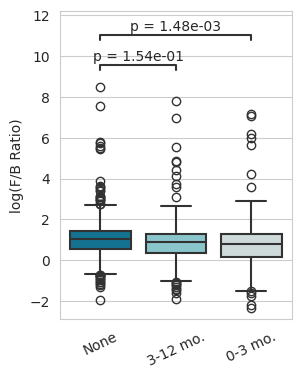

In [17]:
sns.set_style("whitegrid")
sns.despine()

comparisons = [('none', 'three'), ('none', 'twelve')]
x_labels = ['None', '3-12 mo.', '0-3 mo.']
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}
order = ['none', 'twelve', 'three']

fig, ax = plt.subplots(1, 1, figsize=(3, 4))
sns.boxplot(data=fb_ratio_covar, x='abx_recency', y='log_fb_ratio', showfliers=True,
           hue='abx_recency', palette=my_pal, order=order, linewidth=1.5)
current_xticks = ax.get_xticks()
ax.set_xticks(current_xticks, labels=x_labels, rotation=25)
ax.set_xlabel('')
ax.set_ylabel('log(F/B Ratio)')

# Define q-value list
pvalues = [tests_threemo_fb.p.iloc[0], tests_twelvemo_fb.p.iloc[0]]
formatted_pvalues = [f"p = {p:.2e}" for p in pvalues]

# Annotate
annotator = Annotator(ax, comparisons, data=fb_ratio_covar, x='abx_recency', y='log_fb_ratio', order=order)
annotator.set_custom_annotations(formatted_pvalues)
annotator.annotate()

plt.rcParams.update({
    "font.size": 12,
    # "axes.titlesize": 18,
    "axes.labelsize": 16,
    # "ytick.labelsize": 12,
    # "legend.fontsize": 12
})

# plt.savefig("figures/log_fb_ratio.pdf") 
plt.show()

## Determine prevalence filtering thresholds

In [18]:
# relative_abundance

In [19]:
relative_abundance.reset_index(inplace=True)
relative_abundance.to_csv("data/rh_abx_data_rel_abundance.csv", index=False)
relative_abundance.set_index("public_client_id",inplace=True)

In [20]:
# Set microbe features here and at the end of prevalence filtering
microbe_features = relative_abundance.columns
print(len(microbe_features))

514


In [21]:
# Determine prevalence filtering thresholds
# By calculating sparsity
seventy_thresh = (relative_abundance[microbe_features].eq(0).sum() /   # Keep bugs in 70%+ of samples
                  relative_abundance.shape[0] > 0.3)                   # Remove if missingness over 30%
print(f'A 70% prevalence threshold will remove {seventy_thresh.sum()} taxa, \n retaining {len(microbe_features) - seventy_thresh.sum()} for testing')

A 70% prevalence threshold will remove 452 taxa, 
 retaining 62 for testing


In [22]:
ten_thresh = (relative_abundance[microbe_features].eq(0).sum() /   # Keep bugs in 10%+ of samples
                  relative_abundance.shape[0] > 0.9)    
print(f'A 10% prevalence threshold will remove {ten_thresh.sum()} taxa, \n retaining {len(microbe_features) - ten_thresh.sum()} for testing')

A 10% prevalence threshold will remove 326 taxa, 
 retaining 188 for testing


## CLR transform

**Start with imputation: replace 0s with half the lowest count**

In [23]:
"""
Code to send to Sarah
"""
# microbe_features = ten_thresh[~ten_thresh].index 
# zero_mask = relative_abundance == 0                       # Which have zero count
# min_nonzero = relative_abundance[~zero_mask].min().min()  # Find min
# relative_abundance[zero_mask] = min_nonzero / 2           # Impute 0 counts with half of min
# # Calculate geometric mean
# relative_abundance['gmean'] = relative_abundance.apply(
#     scipy.stats.mstats.gmean, axis=1, nan_policy='omit') 

# # CLR transform
# relative_abundance[microbe_features] = np.log(    # Log transform all but gmean column
#     relative_abundance[microbe_features].divide(  # Divide all but gmean column
#         relative_abundance['gmean'], axis=0))

# # Drop helper column
# relative_abundance.drop(["gmean"],axis=1,inplace=True)
# relative_abundance.head()

# relative_abundance_masked = relative_abundance.copy()

# relative_abundance_masked[zero_mask] = np.nan
# relative_abundance_masked.head()
# microbes_masked = relative_abundance_masked.drop(columns=ten_thresh[ten_thresh].index) # Nan mask overlaid

# microbes_merged = abx_covar.merge(microbes_masked, on="public_client_id")

'\nCode to send to Sarah\n'

In [24]:
# List of taxa names over 10% prevalence
# microbe_features_filtered = ten_thresh[~ten_thresh].index 

In [25]:
# set(microbe_features_filtered)

In [26]:
zero_mask = relative_abundance == 0                       # Which have zero count
min_nonzero = relative_abundance[~zero_mask].min().min()  # Find min
relative_abundance[zero_mask] = min_nonzero / 2           # Impute 0 counts with half of min

In [27]:
# Calculate geometric mean
relative_abundance['gmean'] = relative_abundance.apply(
    scipy.stats.mstats.gmean, axis=1, nan_policy='omit') 

# CLR transform
relative_abundance[microbe_features] = np.log(    # Log transform all but gmean column
    relative_abundance[microbe_features].divide(  # Divide all but gmean column
        relative_abundance['gmean'], axis=0))

# Drop helper column
relative_abundance.drop(["gmean"],axis=1,inplace=True)
relative_abundance.head()

,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_nan,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanomethylophilus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Acidimicrobiia_Microtrichales_nan_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinobaculum,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,...,Bacteria_Tenericutes_Mollicutes_EMP-G18_nan_nan,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Tenericutes_Mollicutes_nan_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_nan_nan_nan
public_client_id,,,,,,,,,,,,,,,,,,,,,
01001661,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,...,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,5.488505,-1.031045,-1.031045
01001798,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,2.833927,...,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075
01002183,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,...,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,7.246554,-1.279866,-1.279866
01002412,8.289757,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,4.786304,...,-1.582514,7.243326,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,2.746084,-1.582514,-1.582514
01002885,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,...,-1.369044,-1.369044,6.053284,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044


In [28]:
relative_abundance_masked = relative_abundance.copy()

Overlay mask to replace the bugs that were not present in the count matrix.

In [29]:
relative_abundance_masked[zero_mask] = np.nan
relative_abundance_masked.head()

,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_nan,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanomethylophilus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Acidimicrobiia_Microtrichales_nan_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinobaculum,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,...,Bacteria_Tenericutes_Mollicutes_EMP-G18_nan_nan,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Tenericutes_Mollicutes_nan_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_nan_nan_nan
public_client_id,,,,,,,,,,,,,,,,,,,,,
01001661,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.488505,NaN,NaN
01001798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.833927,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
01002183,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.246554,NaN,NaN
01002412,8.289757,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.786304,...,NaN,7.243326,NaN,NaN,NaN,NaN,NaN,2.746084,NaN,NaN
01002885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,6.053284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Execute Prevalence filtering

In [30]:
microbes = relative_abundance.drop(columns=ten_thresh[ten_thresh].index)               # Kept imputed values
microbes_masked = relative_abundance_masked.drop(columns=ten_thresh[ten_thresh].index) # Nan mask overlaid

In [31]:
# microbes['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides'].hist()

In [32]:
# microbes_masked['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides'].hist()

## Prepare data for linear regression

In [33]:
# Remove hyphen; it stops the regression
microbes_masked.columns = microbes_masked.columns.str.replace("-","")
microbes_masked.columns = microbes_masked.columns.str.replace("/","_")
microbe_features_filtered = microbes_masked.columns.tolist()

In [34]:
# Add covariates back in
microbes_merged = abx_covar.merge(microbes_masked, on="public_client_id")

In [35]:
len(microbe_features_filtered)

188

In [36]:
microbes_merged.to_csv('../data/rh_microbes_clr.csv', index=False)

## Run linear regressions

In [37]:
args = microbe_features_filtered
df = microbes_merged.set_index(['public_client_id'])

In [38]:
microbes_merged.abx_recency.value_counts()

abx_recency
none      1221
twelve     429
three      320
Name: count, dtype: int64

In [39]:
len(microbe_features_filtered)

188

In [40]:
# Define formula for results and look at the difference between including GFR vs not 
formula = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
           "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) + "
           "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + C(vendor_dashboard)")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"
meds_chol = "C(meds_cholesterol)[T.Yes]"
meds_sugar = "C(meds_blood_sugar)[T.Yes]"

In [41]:
tests_threemo_abx = run_tests(args, df, formula, abx_term_three)

Output()

In [42]:
tests_twelvemo_abx = run_tests(args, df, formula, abx_term_twelve)

Output()

In [43]:
tests_meds_chol = run_tests(args, df, formula, meds_chol)

Output()

In [44]:
tests_meds_sugar = run_tests(args, df, formula, meds_sugar)

Output()

### Look at results

In [45]:
microbe_three_small = tests_threemo_abx[tests_threemo_abx["q"]<0.1].sort_values(by='q')

In [46]:
len(tests_threemo_abx[tests_threemo_abx["q"]<0.1].sort_values(by='q'))

73

In [47]:
microbe_twelve_small = tests_twelvemo_abx[tests_twelvemo_abx["q"]<0.1].sort_values(by='q')

In [48]:
len(tests_twelvemo_abx[tests_twelvemo_abx["q"]<0.1].sort_values(by='q'))

37

In [49]:
microbe_chol_small = tests_meds_chol[tests_meds_chol["q"]<0.1].sort_values(by='q')

In [50]:
len(tests_meds_chol[tests_meds_chol["q"]<0.1].sort_values(by='q'))

4

In [51]:
microbe_sugar_small = tests_meds_sugar[tests_meds_sugar["q"]<0.1].sort_values(by='q')

In [52]:
len(microbe_sugar_small)

13

### Create CLR abundance boxplots for fig 2

In [53]:
microbes_clr = abx_covar.merge(microbes_masked, on="public_client_id")

In [54]:
sns.set_style(style="whitegrid",  rc={"xtick.bottom": False, 'ytick.left': True})
order = ['none', 'twelve', 'three']
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}
comparisons = [('none', 'three'), ('none', 'twelve')]
x_labels = ['None', '3-12 mo.', '0-3 mo.']

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 2.23e-05
none vs. three: q = 4.60e-08


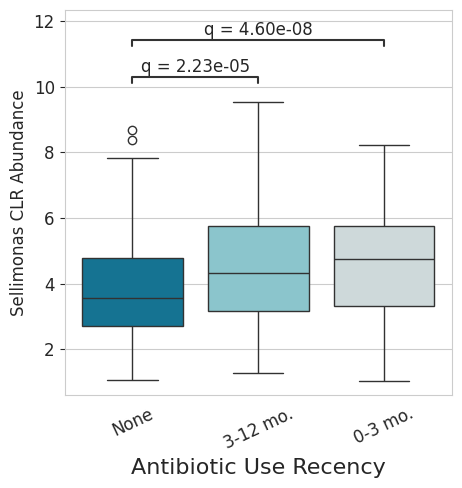

In [55]:
plt.figure(figsize=(5, 5))
bug ='Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas'
ax = sns.boxplot(data=microbes_clr, x='abx_recency', y=bug,
            hue='abx_recency', palette=my_pal, order=order, )

current_xticks = ax.get_xticks()
ax.set_xticks(current_xticks, labels=x_labels, rotation=25)
ax.set_xlabel('Antibiotic Use Recency')
ax.set_ylabel(f'{bug.split('_')[-1]} CLR Abundance', size=12)

# Define q-value list
three_bug = tests_threemo_abx[tests_threemo_abx['feature']==bug]
twelve_bug = tests_twelvemo_abx[tests_twelvemo_abx['feature']==bug]

qvalues = [three_bug.q.iloc[0], twelve_bug.q.iloc[0]]
formatted_qvalues = [f"q = {q:.2e}" for q in qvalues]

# Annotate
annotator = Annotator(ax, comparisons, data=microbes_clr, x='abx_recency', y=bug, order=order)
annotator.set_custom_annotations(formatted_qvalues)
annotator.annotate()

plt.savefig("figures/CLR_sellimonas.pdf", bbox_inches="tight")

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 3.67e-02
none vs. three: q = 8.76e-03


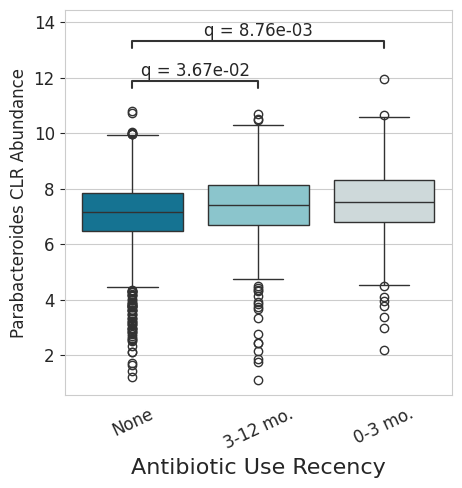

In [56]:
plt.figure(figsize=(5, 5))
bug ='Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides'
ax = sns.boxplot(data=microbes_clr, x='abx_recency', y=bug,
            hue='abx_recency', palette=my_pal, order=order)

current_xticks = ax.get_xticks()
ax.set_xticks(current_xticks, labels=x_labels, rotation=25)
ax.set_xlabel('Antibiotic Use Recency')
ax.set_ylabel(f'{bug.split('_')[-1]} CLR Abundance', size=12)

# Define q-value list
three_bug = tests_threemo_abx[tests_threemo_abx['feature']==bug]
twelve_bug = tests_twelvemo_abx[tests_twelvemo_abx['feature']==bug]

qvalues = [three_bug.q.iloc[0], twelve_bug.q.iloc[0]]
formatted_qvalues = [f"q = {q:.2e}" for q in qvalues]

# Annotate
annotator = Annotator(ax, comparisons, data=microbes_clr, x='abx_recency', y=bug, order=order)
annotator.set_custom_annotations(formatted_qvalues)
annotator.annotate()

plt.savefig("figures/CLR_parabacteroides.pdf", bbox_inches="tight")

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 3.78e-04
none vs. three: q = 3.18e-05


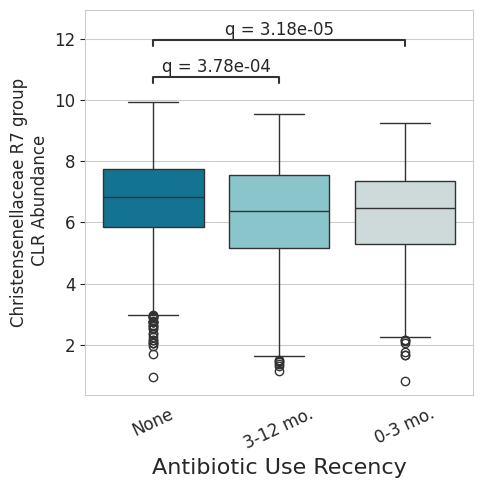

In [57]:
plt.figure(figsize=(5, 5))
bug ='Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group'

ax = sns.boxplot(data=microbes_clr, x='abx_recency', y=bug,
            hue='abx_recency', palette=my_pal, order=order)

current_xticks = ax.get_xticks()
ax.set_xticks(current_xticks, labels=x_labels, rotation=25)
ax.set_xlabel('Antibiotic Use Recency')
ax.set_ylabel(f'{bug.split('_')[5]} {bug.split('_')[6]} {bug.split('_')[7]}\n CLR Abundance', size=12)

# Define q-value list
three_bug = tests_threemo_abx[tests_threemo_abx['feature']==bug]
twelve_bug = tests_twelvemo_abx[tests_twelvemo_abx['feature']==bug]

qvalues = [three_bug.q.iloc[0], twelve_bug.q.iloc[0]]
formatted_qvalues = [f"q = {q:.2e}" for q in qvalues]

# Annotate
annotator = Annotator(ax, comparisons, data=microbes_clr, x='abx_recency', y=bug, order=order)
annotator.set_custom_annotations(formatted_qvalues)
annotator.annotate()

plt.savefig("figures/CLR_christensenellaceae.pdf", bbox_inches="tight")

## Create dfs for use in R (plot with complex heatmap)

**Beta coefficient dataframe**

In [64]:
# Obtain bugs significant for any cov
sig_microbes = list(set(microbe_three_small['feature'].tolist() + 
                   microbe_twelve_small['feature'].tolist() + 
                   microbe_chol_small['feature'].tolist() + 
                   microbe_sugar_small['feature'].tolist()))

# Add three month betas
microbe_betas = tests_threemo_abx[['feature','beta']].copy().rename(
     columns={'beta':'abx_three'})

# Add twelve month betas
microbe_betas = microbe_betas.merge(tests_twelvemo_abx[['feature','beta']].copy(),
                                    how='left', on='feature').rename(
     columns={'beta':'abx_twelve'})

# Add cholesterol medication use betas
microbe_betas = microbe_betas.merge(tests_meds_chol[['feature','beta']].copy(),
                                    how='left', on='feature').rename(
     columns={'beta':'meds_cholesterol'})
# Add blood sugar medication use betas
microbe_betas = microbe_betas.merge(tests_meds_sugar[['feature','beta']].copy(),
                                    how='left', on='feature').rename(
     columns={'beta':'meds_blood_sugar'})

microbe_betas = microbe_betas[microbe_betas.feature.isin(sig_microbes)]

**q-value dataframe**

In [65]:
# Add three month 
microbe_q_values = tests_threemo_abx[['feature','q']].copy().rename(
     columns={'q':'abx_three'})

# Add twelve month 
microbe_q_values = microbe_q_values.merge(tests_twelvemo_abx[['feature','q']].copy(),
                                    how='left', on='feature').rename(
     columns={'q':'abx_twelve'})

# Add cholesterol medication use 
microbe_q_values = microbe_q_values.merge(tests_meds_chol[['feature','q']].copy(),
                                    how='left', on='feature').rename(
     columns={'q':'meds_cholesterol'})

# Add blood sugar medication use 
microbe_q_values = microbe_q_values.merge(tests_meds_sugar[['feature','q']].copy(),
                                    how='left', on='feature').rename(
     columns={'q':'meds_blood_sugar'})

In [66]:
microbe_q_values = microbe_q_values[microbe_q_values['feature'].isin(sig_microbes)]

**Add plot name to both dfs**

In [61]:
# microbe_betas[microbe_betas['feature']=='Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pseudoflavonifractor']

In [62]:
# microbe_q_values[microbe_q_values['feature']=='Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pseudoflavonifractor']

In [67]:
# For the microbe linear regression heatmap that needs all data tested
microbe_betas['plot_name'] = microbe_betas['feature'].apply(lambda x: microbe_dict[x])
microbe_q_values['plot_name'] = microbe_q_values['feature'].apply(lambda x: microbe_dict[x])

In [68]:
taxa_grab_phyla = pd.read_csv("../data/tax_genus_level.csv")

In [70]:
taxa_grab_phyla.loc[:,'taxa_genus_level'] = taxa_grab_phyla.loc[:,'taxa_genus_level'].str.replace("-","")
taxa_grab_phyla.loc[:,'taxa_genus_level'] = taxa_grab_phyla.loc[:,'taxa_genus_level'].str.replace("/","_")

In [77]:
microbe_betas = microbe_betas.merge(taxa_grab_phyla, how = 'left', left_on='feature',
                                    right_on='taxa_genus_level')
microbe_betas.drop(columns='taxa_genus_level', inplace=True)

In [78]:
taxa_prevalence = microbes_masked[microbe_features_filtered].notna().sum() / microbes_masked[microbe_features_filtered].shape[0]

In [79]:
taxa_prevalence['Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella']

0.6055837563451777

In [80]:
microbe_betas['prevalence'] = microbe_betas['feature'].apply(lambda x: taxa_prevalence[x])
microbe_betas['prevalence_bins'] = pd.cut(microbe_betas.prevalence, [0.035, .25, .5, .75, 0.975])

In [81]:
# Use this cell to check min and max values for cbar in heatmap
microbe_betas.iloc[:, 1:5].max()

abx_three           0.881916
abx_twelve          0.716288
meds_cholesterol    0.576346
meds_blood_sugar    2.577253
dtype: float64

In [82]:
microbe_betas.iloc[:, 1:5].min()

abx_three          -0.591867
abx_twelve         -0.413830
meds_cholesterol   -1.727472
meds_blood_sugar   -0.697588
dtype: float64

In [85]:
# microbe_betas

In [86]:
# Save csvs
microbe_betas.to_csv("../data/microbe_betas_sugar_chol_abx_10percent.csv", index=False)
microbe_q_values.to_csv("../data/microbe_qs_sugar_chol_abx_10percent.csv", index=False)